In [3]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import calendar


In [4]:
# Import the data
booking_data = pd.read_csv("../data/Hotel_bookings.csv")

In [ ]:
print (booking_data.head(5))

   IsCanceled  LeadTime  ArrivalDateYear ArrivalDateMonth  \
0           0         6             2015             July   
1           1        88             2015             July   
2           1        65             2015             July   
3           1        92             2015             July   
4           1       100             2015             July   

   ArrivalDateWeekNumber  ArrivalDateDayOfMonth  StaysInWeekendNights  \
0                     27                      1                     0   
1                     27                      1                     0   
2                     27                      1                     0   
3                     27                      1                     2   
4                     27                      2                     0   

   StaysInWeekNights  Adults  Children  ...      DepositType        Agent  \
0                  2       1       0.0  ...  No Deposit                 6   
1                  4       2       0.0  

In [ ]:
print (booking_data.describe())

         IsCanceled      LeadTime  ArrivalDateYear  ArrivalDateWeekNumber  \
count  79330.000000  79330.000000     79330.000000           79330.000000   
mean       0.417270    109.735724      2016.174285              27.177449   
std        0.493111    110.948526         0.699181              13.398523   
min        0.000000      0.000000      2015.000000               1.000000   
25%        0.000000     23.000000      2016.000000              17.000000   
50%        0.000000     74.000000      2016.000000              27.000000   
75%        1.000000    163.000000      2017.000000              38.000000   
max        1.000000    629.000000      2017.000000              53.000000   

       ArrivalDateDayOfMonth  StaysInWeekendNights  StaysInWeekNights  \
count           79330.000000          79330.000000       79330.000000   
mean               15.786625              0.795185           2.182957   
std                 8.728451              0.885026           1.456416   
min           

In [ ]:
print (booking_data.info())

<class 'pandas.DataFrame'>
RangeIndex: 79330 entries, 0 to 79329
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   79330 non-null  int64  
 1   LeadTime                     79330 non-null  int64  
 2   ArrivalDateYear              79330 non-null  int64  
 3   ArrivalDateMonth             79330 non-null  str    
 4   ArrivalDateWeekNumber        79330 non-null  int64  
 5   ArrivalDateDayOfMonth        79330 non-null  int64  
 6   StaysInWeekendNights         79330 non-null  int64  
 7   StaysInWeekNights            79330 non-null  int64  
 8   Adults                       79330 non-null  int64  
 9   Children                     79326 non-null  float64
 10  Babies                       79330 non-null  int64  
 11  Meal                         79330 non-null  str    
 12  Country                      79306 non-null  str    
 13  MarketSegment              

> 💡 **Data Exploration and Analysis**

In [ ]:
# See the unique values of each column
# The aim for this is to see if missing values (not null) in any column like having 0s when it shouldn't
for column in booking_data.columns:
    print(f"Unique values in {column}: {booking_data[column].unique()}")

Unique values in IsCanceled: [0 1]
Unique values in LeadTime: [  6  88  65  92 100  79   3  63  62  43   4  97  80  60 106  68  18  71
  85  75  89  83  72 111  86  73  55  69  76  61  77  54  90 117 105  51
  24  84 115  67  87 109  96 114  66  59 122 123  94 120   0 125  82 107
 103  12 118 108 119  20  22  99 112  93 132 110   2  15  98 124  16  19
  81   5  27  25 126  74   1  64 138 102  78 130 135   7  28  34 141  33
 101  13  11  36 128  30 145 142  39 121 147 140 104  41 134 150   8 133
  10  40 131   9 137 127  46  47  14 151  17  44 113  53  50 162 148 149
  21  23  37  49  26  32  52 173  45 164  42  58  48 168  31  38 175 170
  29  35 167 166  56 152 155 116  95  57 179  70 192 169 193 199 204 200
  91 198 158 210 156 174 184 180 195 216 233 212 139 242 208 146 144 159
 197 129 160 154 393 251 157 161 136 182 267 274 268 190 281 188 275 270
 265 288 143 295 443 194 437 253 207 302 259 178 289 298 286 309 196 273
 276 297 191 451 217 323 316 189 322 211 163 172 153 205 202 3

> 💡 **Data insights**

In [ ]:
# IsCanceled => No issues or anomalies.
# LeadTime => It has 0s. However, this is totally valid as 0 means that customer has arrived in the same date of entering the PMS. 
# ArrivalDateYear => No issues or anomalies.
# ArrivalDateMonth => No issues or anomalies.
# ArrivalDateWeekNumber => has values of (53). Is this valid? [Note: A year has only 52 years].
# ArrivalDateDayOfMonth => No issues or anomalies as all values range between 1-31. However, we still need to check for inconsistencies like 31st Feb, 30th Feb, 31st April, and so on.
# StaysInWeekendNights => No issues or anomalies. "0" here has a meaning. 
# StaysInWeekNights => No issues or anomalies. "0" here has a meaning.
# Adults => It has 0s. How a reservation can be made with 0 adults?
# Children => It has 4 missing values. These rows need to be removed.
# Babies => Bookings with 9 and 10 babies? Wow. May be outliers! 
# Meal => No issues or anomalies
# Country => It has 24 missing values and rare classes with 1 existance. May need to be removed. 
# MarketSegment => There is no Nulls, however, the 8th class (Undefined) has found in only 2 rows which most probably will be removed to avoid noise. 
# DistributionChannel => There is no Nulls, however, the 5th class (Undefined) has found in only 4 rows which most probably will be removed to avoid noise. 
# IsRepeatedGuest => No issues or anomalies.
# PreviousCancellations => No missing values, however, the values 11, 13, and 21 may be outliers. Note: "0" has a meaning.
# PreviousBookingsNotCanceled => No missing values, may have outlies (will be discoved from BoxPlot). Note: "0" has a meaning.
# ReservedRoomType => No missing values or anomalies.
# AssignedRoomType => No missing values. Having a new room type "K" which didn't exist in "ReservedRoomType" is totally normal. It may be an operational or upgrade room that offered by the hotel itself and not available for publics for reservation.
# BookingChanges => No incorrect values or missing ones. However, values like "20" may be outliers and cause skewness of data. So, outliers may be removed.
# DepositType => No wrong categories or missing values.
# Agent => It has 8131 "NULL" values. However, this is fine as "NULL" here means that the customer made the reservation itself without any travel agent. We still need to investigate on how "NULL" should be presented. It may have to be replaced with other category like "Direct" for example. Note: For linear models, we may use "Target Encoding" to replace the "NULL" values with the mean of the target variable (IsCanceled) for that category.
# Company => It has 75641 "NULL" values. This is fine and means that customer didn't book through a company.
# DaysInWaitingList => 0 has a meaning here. So, all data values are valid. However, we need to check for outliers.
# CustomerType => No missing values or anomalies.
# ADR => It has 1208 "0" values. 1079 of them weren't cancelled. Were they free stays? [We need to handle this].
# RequiredCarParkingSpaces => No issues in the data.
# TotalOfSpecialRequests => No issues in the data. 
# ReservationStatus => No isses. All data values fall within the original cited categories.
# ReservationStatusDate => No issues in the data.

In [ ]:
Q1 = booking_data['PreviousCancellations'].quantile(0.25)
Q3 = booking_data['PreviousCancellations'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR
print("Upper Bound (Max non-outlier):", upper_bound)

Upper Bound (Max non-outlier): 0.0


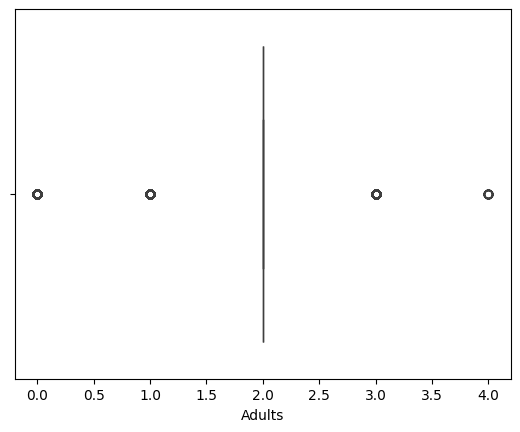

Adults
2    58255
1    15879
3     4775
0      390
4       31
Name: count, dtype: int64


In [ ]:
sns.boxplot(x= booking_data['Adults'])

plt.show()
print (booking_data['Adults'].value_counts())

In [ ]:
zero_nights_condition = (booking_data['StaysInWeekNights'] == 0) & (booking_data['StaysInWeekendNights'] == 0)
print(booking_data[zero_nights_condition & (booking_data['IsCanceled'] == 1)]['ReservationStatus'].value_counts())

ReservationStatus
Canceled    16
No-Show      7
Name: count, dtype: int64


In [ ]:
# As expected, in all 23 bookings with 0 nights, the reservation status is "Canceled". This is a valid case as the customer may have made a reservation and then canceled it before arriving at the hotel:
# 16 => Cancelled by the customer.
# 7 => Cancelled by the hotel as  customer didn't arrive at the hotel (No-Show). 
# The other uncancelled 308 bookings will be removed.

In [ ]:
# Let's get the number of bookings with 0 ADR and see if they are cancelled or not.
print(booking_data[booking_data['ADR'] == 0]['IsCanceled'].value_counts())

IsCanceled
0    1079
1     129
Name: count, dtype: int64


In [ ]:
# Let's get the number of bookings with 0 adults and see if they are cancelled or not.
print (booking_data[(booking_data['Adults'] == 0) & (booking_data['Children'] > 0) & (booking_data['Babies'] == 0)]['IsCanceled'].value_counts())

IsCanceled
0    137
1     83
Name: count, dtype: int64


In [ ]:
# Uh! There are 390 bookings with 0 adults:
# 107 of them are cancelled (Make sense).
# 283 of them are not cancelled which means that they are confirmed without any adults. This is a serious anomaly and may need to be removed from the dataset.

In [ ]:
# Let's get the number of bookings with 0 adults, 0 children, and 0 babies and see if they are cancelled or not (Edge case)
print (booking_data[(booking_data['Adults'] == 0) & (booking_data['Children'] == 0) & (booking_data['Babies'] == 0)]['IsCanceled'].value_counts())

IsCanceled
0    144
1     23
Name: count, dtype: int64


In [ ]:
# There are 144 bookings made already and not cancelled without any adults, children, or babies.
# Note: These rows will be removed most probably as they are not valid bookings.

In [ ]:
# Let's see the number of bookings made with children only.
print (booking_data[(booking_data['Adults'] == 0) & (booking_data['Children'] > 0) & (booking_data['Babies'] == 0)]['IsCanceled'].value_counts())

IsCanceled
0    137
1     83
Name: count, dtype: int64


In [ ]:
# We have 137 booking with children only. These rows will be most probably removed as they are invalid.

In [ ]:
booking_data.dtypes.value_counts()

int64      16
str        13
float64     2
Name: count, dtype: int64

In [ ]:
booking_data.select_dtypes(include='float').columns.tolist()

['Children', 'ADR']

In [ ]:
# Number of children should be int not float
booking_data[booking_data['Children'] % 1 != 0]

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
540,1,2,2015,August,32,3,1,0,2,NaN,...,No Deposit,NULL,NULL,0,Transient-Party,12.0,0,1,Canceled,2015-08-01
607,1,1,2015,August,32,5,0,2,2,NaN,...,No Deposit,14,NULL,0,Transient-Party,12.0,0,1,Canceled,2015-08-04
619,1,1,2015,August,32,5,0,2,3,NaN,...,No Deposit,NULL,NULL,0,Transient-Party,18.0,0,2,Canceled,2015-08-04
1100,1,8,2015,August,33,13,2,5,2,NaN,...,No Deposit,9,NULL,0,Transient-Party,76.5,0,1,Canceled,2015-08-09


In [ ]:
# The column got a float data type because of these NaNs
# There are no float values but the column need to be converted to int after dealing with the NaNs
booking_data['Children'].value_counts()

Children
0.0    74220
1.0     3023
2.0     2024
3.0       59
Name: count, dtype: int64

In [ ]:
booking_data.isna().sum()[booking_data.isna().sum() > 0]
# Children contains 4 NaN and Country contains 24

Children     4
Country     24
dtype: int64

## Duplicates

In [ ]:
booking_data.duplicated().sum()
# The dataset does not include a booking ID, so identical rows may be duplicates and may be similar valid bookings 
# Maybe an agency is booking several identical rooms for its employees at the same time
# This is a leakage risk. If identical rows land in both train and test splits, the model is partly tested on rows it has memorized
# So we must group the duplicates and put each group in the train or test split

np.int64(25902)

In [ ]:
group_sizes = booking_data.groupby(list(booking_data.columns), dropna=False).size()
group_sizes = group_sizes[group_sizes > 1]

print("Number of duplicate groups:", len(group_sizes))
print("\nGroup sizes (largest first):")
print(group_sizes.value_counts().sort_index(ascending=False).head(10))

Number of duplicate groups: 5846

Group sizes (largest first):
180    1
150    1
109    1
101    1
100    1
99     3
89     1
85     3
84     2
79     3
Name: count, dtype: int64


In [ ]:
#  There are 25902 duplicates and they are groups:
# Biggest group => 180 duplicates
# Second biggest group => 150 duplicates 
# .......So on.

# # The Question##
# Do we really need to delete them?
# [Note] They may be just trips for specific agents with many bookings in the same day and we just need to put them all in the train data.

In [ ]:
# Check that number of duplicates in the groups is equal to the number of duplicates in the original dataframe
total_in_groups = group_sizes.sum()
total_from_booking_data = booking_data.duplicated(keep=False).sum()

print("Sum of group sizes:        ", total_in_groups)
print("booking_data.duplicated(keep=False): ", total_from_booking_data)
print("Match:", total_in_groups == total_from_booking_data)

Sum of group sizes:         31748
booking_data.duplicated(keep=False):  31748
Match: True


## Validations


In [ ]:
# Are there Impossible dates?

month_map = {name: i for i, name in enumerate(calendar.month_name)}
month_num = booking_data["ArrivalDateMonth"].map(month_map)

arrival_date = pd.to_datetime(
    dict(year=booking_data["ArrivalDateYear"], month=month_num, day=booking_data["ArrivalDateDayOfMonth"]),
    errors="coerce",
)
print("Impossible dates (31 Feb):", arrival_date.isna().sum())

# No Impossible dates in the data


Impossible dates (31 Feb): 0


In [ ]:
week = booking_data["ArrivalDateWeekNumber"]

week_53 = (week == 53)
print("Rows with week 53:", week_53.sum(), '\n')
arrival_date[week_53].groupby(arrival_date[week_53].dt.year).agg(["min", "max"]) 


Rows with week 53: 1198 



,min,max
2015,2015-12-27,2015-12-31
2016,2016-12-25,2016-12-31


In [ ]:
print("ReservationStatus and IsCanceled: \n")
pd.crosstab(booking_data["ReservationStatus"], booking_data["IsCanceled"])

# The two columns match 

# Important Note ❌ The ReservationStatus must be deleted in classification project because of Leakage audit

ReservationStatus and IsCanceled: 



IsCanceled,0,1
ReservationStatus,,
Canceled,0,32186
Check-Out,46228,0
No-Show,0,916


In [ ]:
prev_can = booking_data["PreviousCancellations"]
prev_nc = booking_data["PreviousBookingsNotCanceled"]
has_history = (prev_can + prev_nc) > 0
print("IsRepeatedGuest and having previous bookings: \n")
pd.crosstab(booking_data["IsRepeatedGuest"], has_history, colnames=["has previous bookings"])

# There are repeated guests without previous bookings whether cancelled or not 


IsRepeatedGuest and having previous bookings: 



has previous bookings,False,True
IsRepeatedGuest,,
0,72492,4806
1,296,1736


In [ ]:
mask = (booking_data["IsRepeatedGuest"] == 0) & (booking_data["PreviousBookingsNotCanceled"] > 0)
print("Not repeated but has previous not-canceled bookings:", mask.sum())

# Also a problem

Not repeated but has previous not-canceled bookings: 173


In [ ]:

print("MarketSegment and DistributionChannel: \n")
pd.crosstab(booking_data["MarketSegment"], booking_data["DistributionChannel"])

# There are many overlaps

MarketSegment and DistributionChannel: 



DistributionChannel,Corporate,Direct,GDS,TA/TO,Undefined
MarketSegment,,,,,
Aviation,227,0,0,10,0
Complementary,69,437,0,36,0
Corporate,2636,56,0,294,0
Direct,6,6048,1,37,1
Groups,240,177,0,13558,0
Offline TA/TO,198,6,45,16498,0
Online TA,32,56,147,38512,1
Undefined,0,0,0,0,2


## > 💡 **Data Visualization**

In [ ]:
num_cols = ["LeadTime", "StaysInWeekendNights", "StaysInWeekNights", "Adults", "Children",
            "Babies", "PreviousCancellations", "PreviousBookingsNotCanceled",
            "BookingChanges", "DaysInWaitingList", "RequiredCarParkingSpaces",
            "TotalOfSpecialRequests", "ADR"]
num = booking_data[num_cols].apply(pd.to_numeric, errors="coerce")

In [ ]:
booking_data.describe()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,BookingChanges,DaysInWaitingList,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests
count,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79326.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000
mean,0.417270,109.735724,2016.174285,27.177449,15.786625,0.795185,2.182957,1.850977,0.091370,0.004941,0.025615,0.079743,0.132371,0.187369,3.226774,105.304465,0.024367,0.546918
std,0.493111,110.948526,0.699181,13.398523,8.728451,0.885026,1.456416,0.509292,0.372177,0.084323,0.157983,0.415472,1.693411,0.608620,20.870890,43.602954,0.154919,0.780776
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,23.000000,2016.000000,17.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,79.200000,0.000000,0.000000
50%,0.000000,74.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,99.900000,0.000000,0.000000
75%,1.000000,163.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,629.000000,2017.000000,53.000000,31.000000,16.000000,41.000000,4.000000,3.000000,10.000000,1.000000,21.000000,72.000000,21.000000,391.000000,5400.000000,3.000000,5.000000


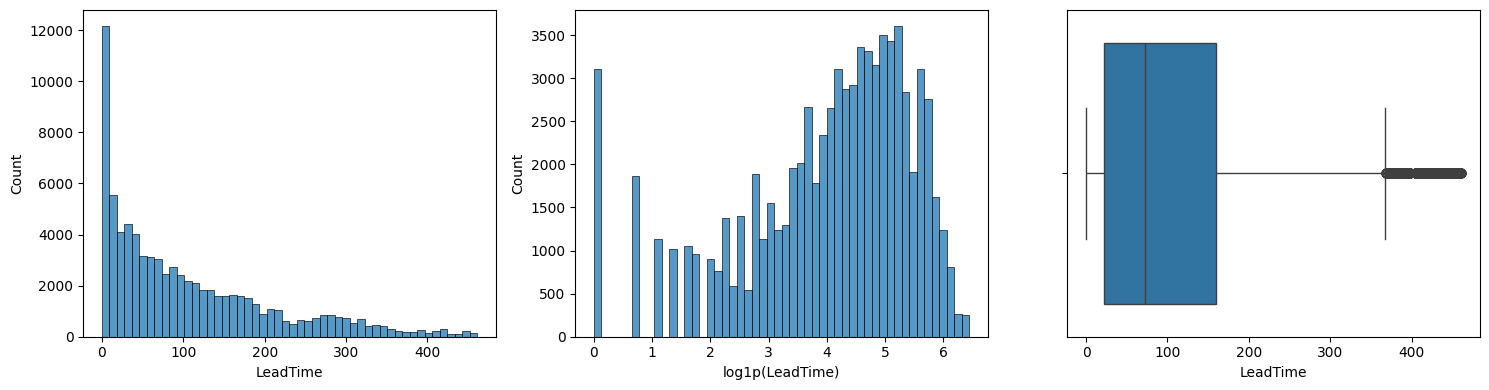

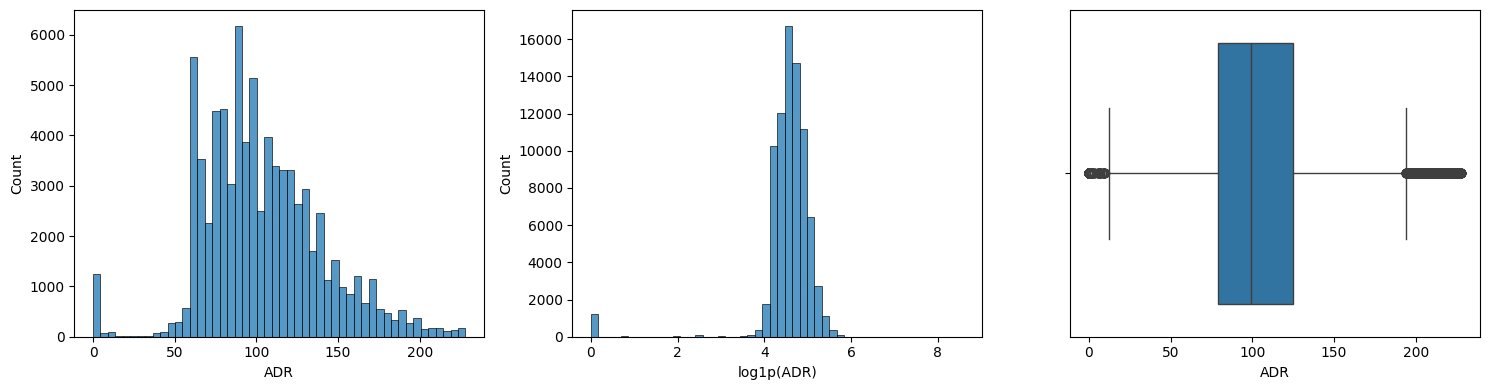

In [ ]:
for c in ["LeadTime", "ADR"]:
    s = num[c]
    p99 = s.quantile(0.99)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    sns.histplot(s[s <= p99], bins=50, ax=axes[0])
    sns.histplot(np.log1p(s), bins=50, ax=axes[1])
    sns.boxplot(x=s[s <= p99], ax=axes[2])

    axes[0].set_xlabel(c)
    axes[1].set_xlabel(f"log1p({c})")
    axes[2].set_xlabel(c)
    plt.tight_layout()

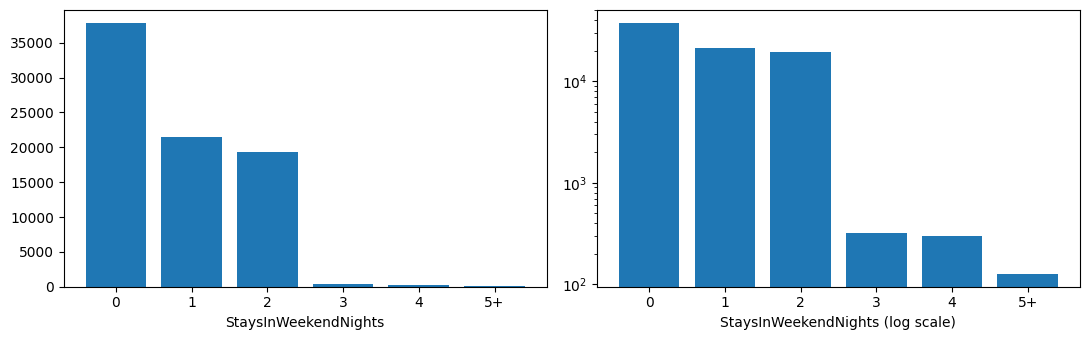

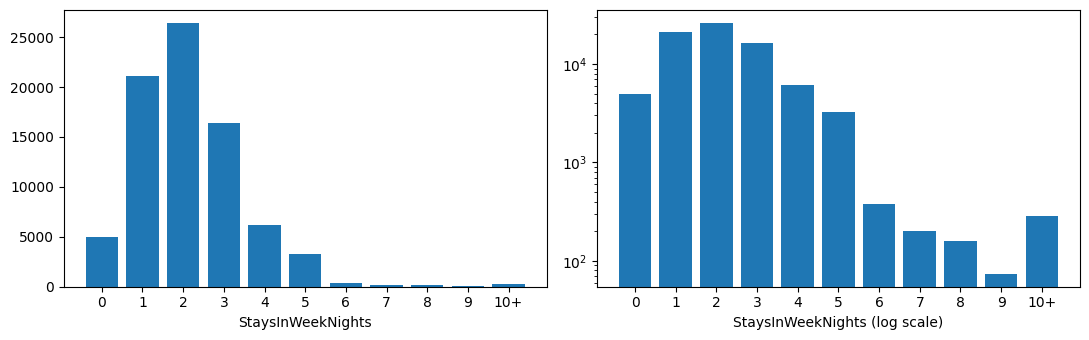

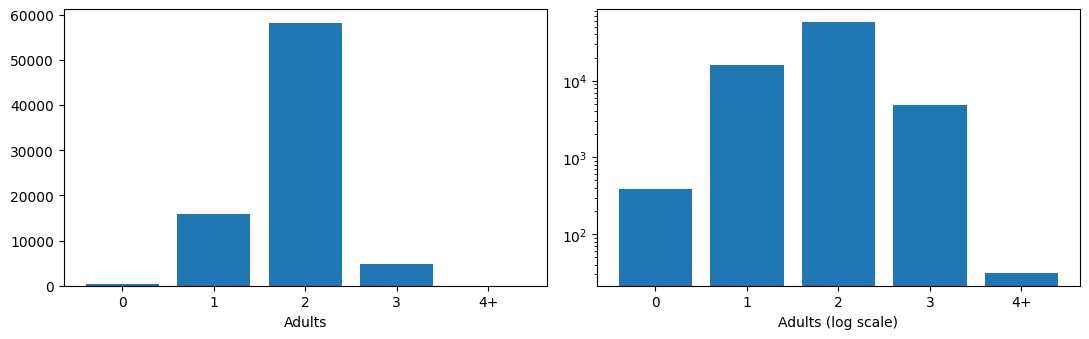

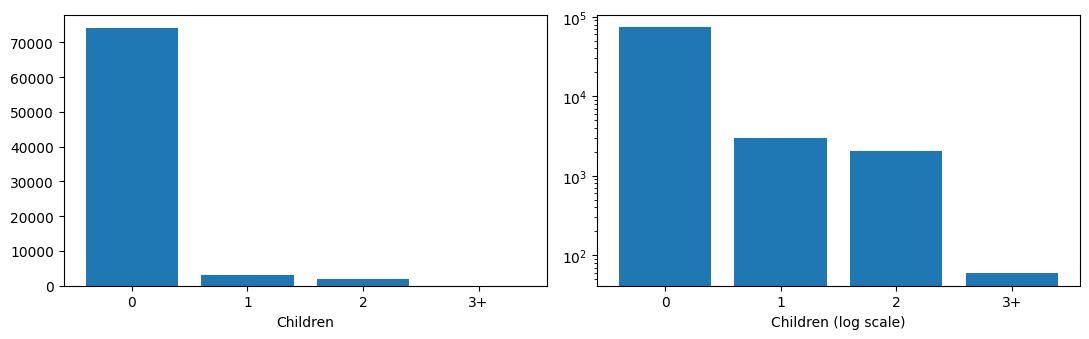

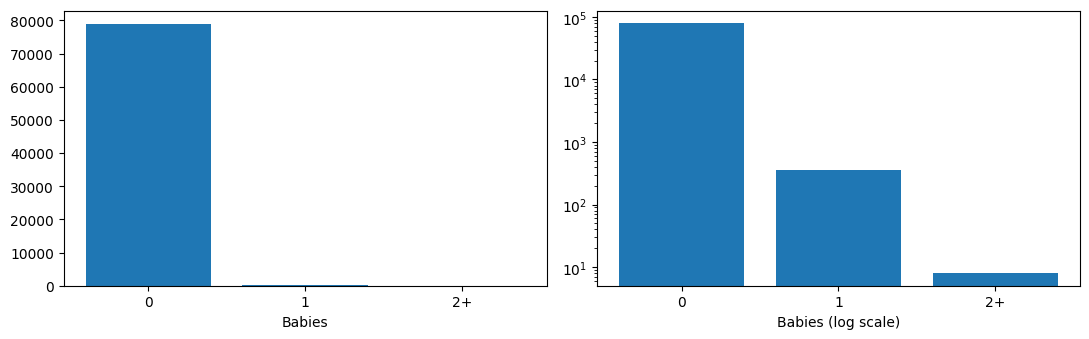

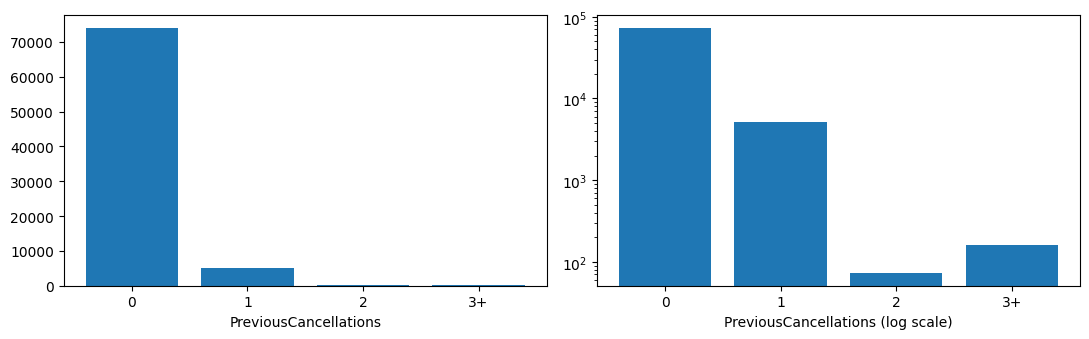

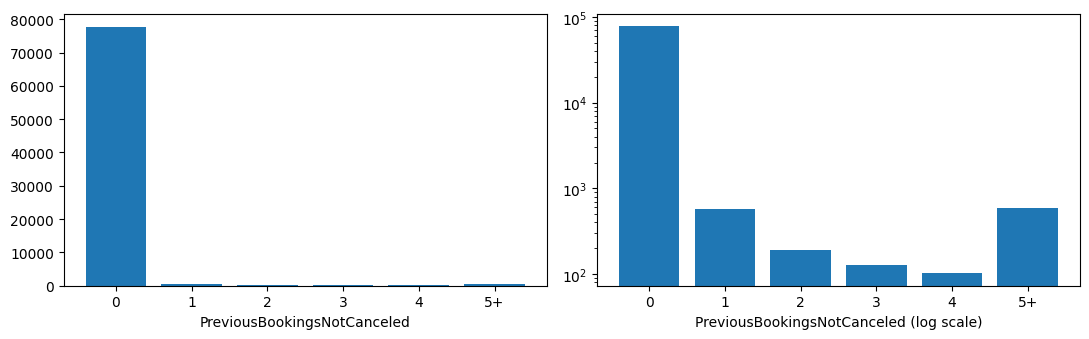

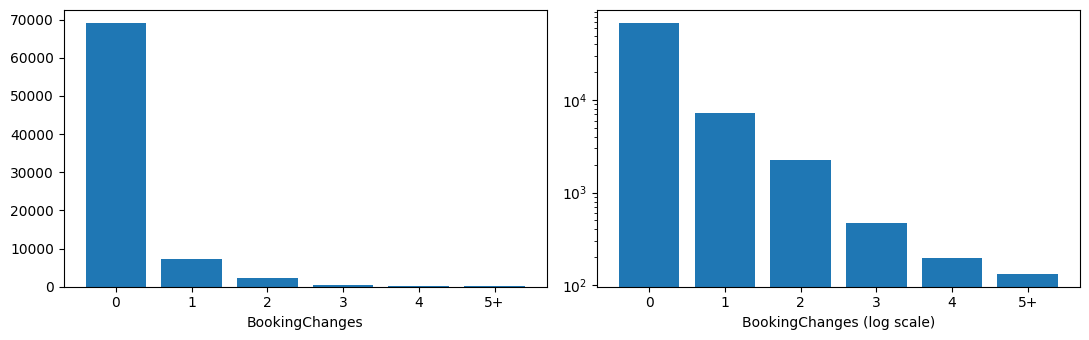

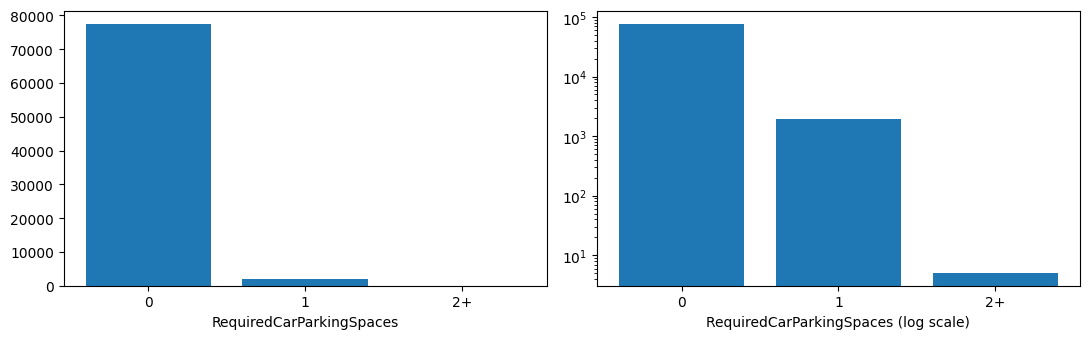

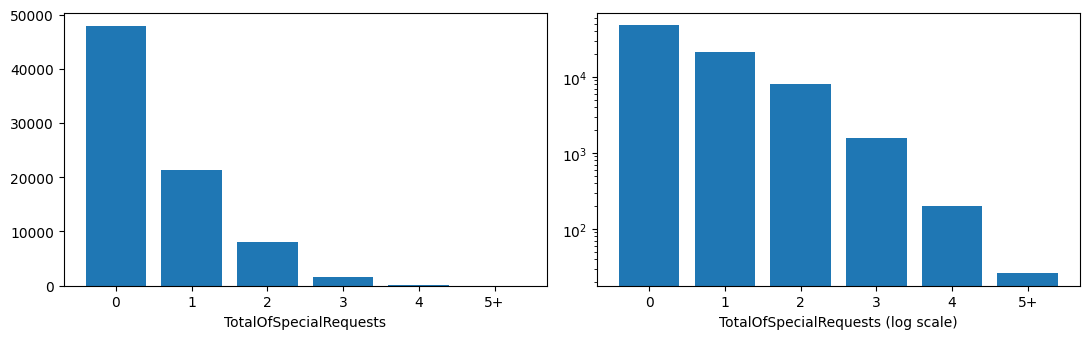

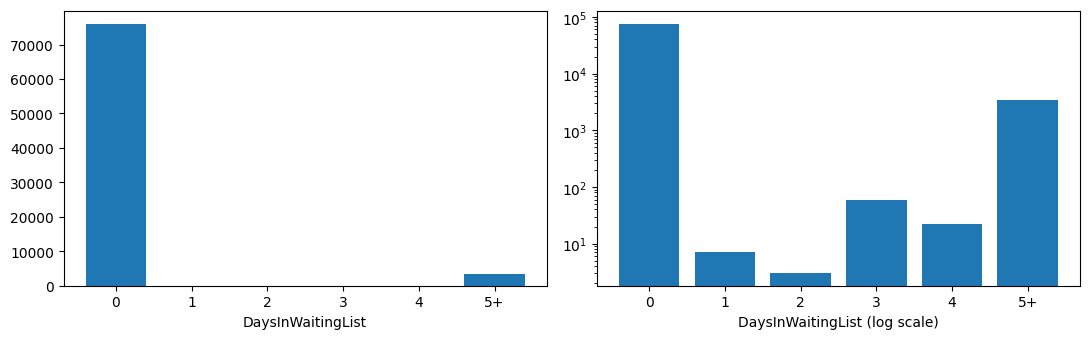

In [ ]:

caps = {"StaysInWeekendNights": 5, "StaysInWeekNights": 10, "Adults": 4, "Children": 3,
        "Babies": 2, "PreviousCancellations": 3, "PreviousBookingsNotCanceled": 5,
        "BookingChanges": 5, "RequiredCarParkingSpaces": 2, "TotalOfSpecialRequests": 5, "DaysInWaitingList": 5}

for c, cap in caps.items():
    s = num[c].dropna().clip(upper=cap)
    counts = s.value_counts().reindex(range(cap + 1), fill_value=0)
    labels = [str(i) for i in range(cap)] + [f"{cap}+"]

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].bar(labels, counts.values)
    axes[1].bar(labels, counts.values)
    axes[1].set_yscale("log")

    axes[0].set_xlabel(c)
    axes[1].set_xlabel(f"{c} (log scale)")
    plt.tight_layout()

# The log scale plots for better visualization (to see the small values) (Not the log1p transformation)

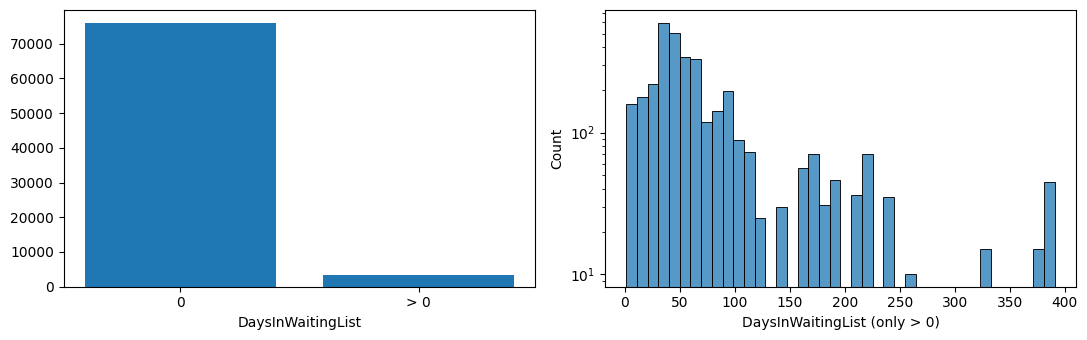

In [ ]:
s = num["DaysInWaitingList"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(["0", "> 0"], [(s == 0).sum(), (s > 0).sum()])
sns.histplot(s[s > 0], bins=40, ax=axes[1])
axes[1].set_yscale("log")

axes[0].set_xlabel("DaysInWaitingList")
axes[1].set_xlabel("DaysInWaitingList (only > 0)")
plt.tight_layout()

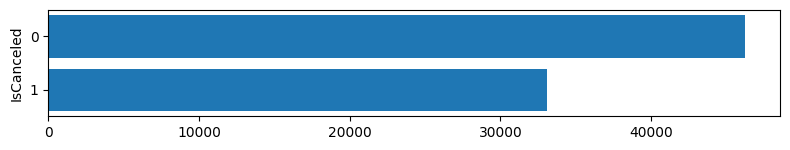

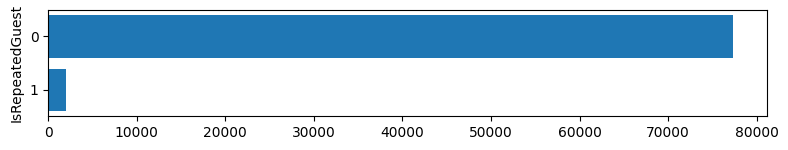

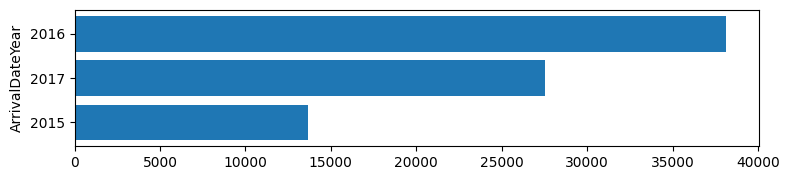

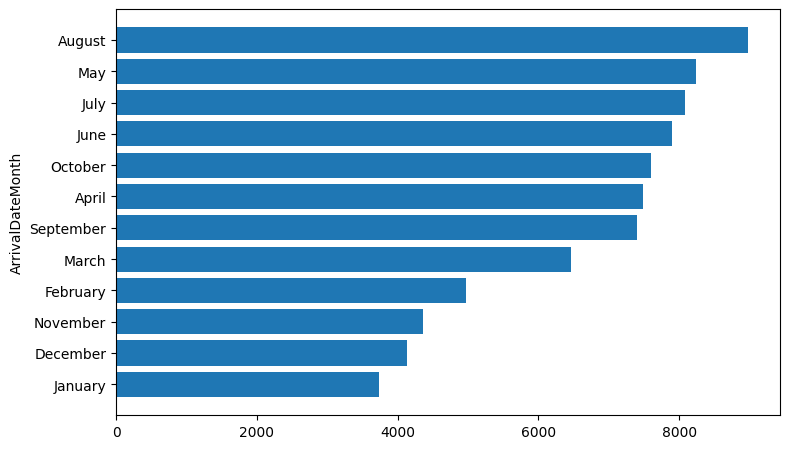

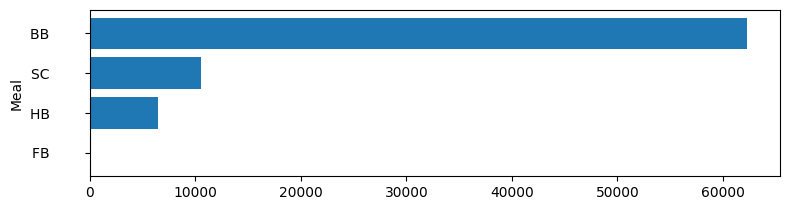

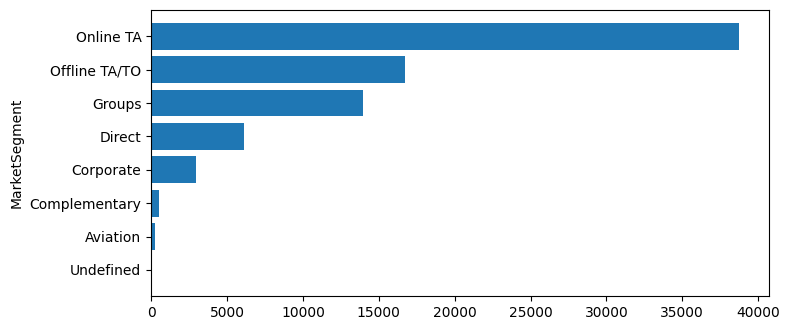

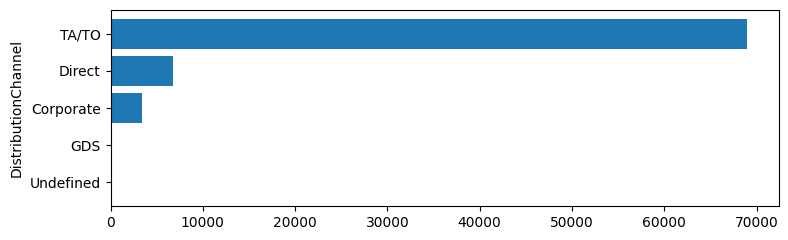

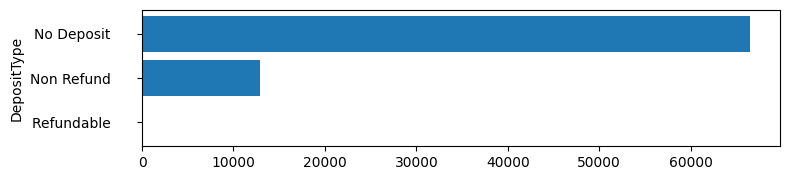

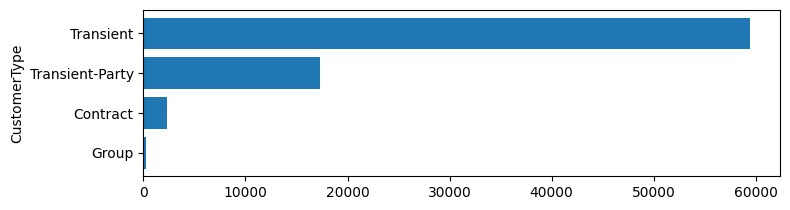

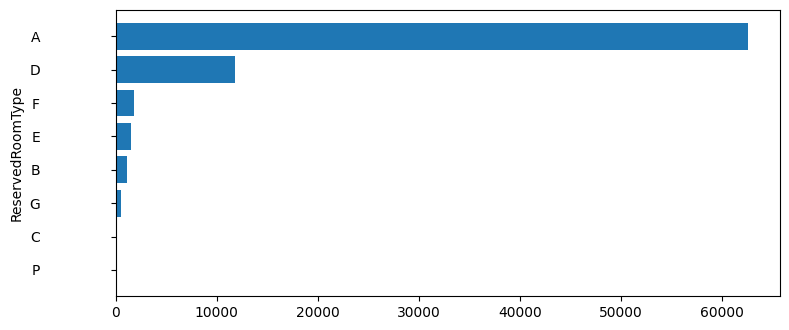

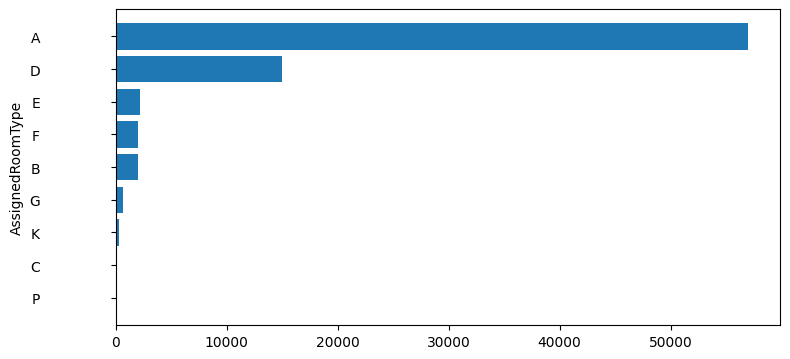

In [ ]:
low_card = ["IsCanceled", "IsRepeatedGuest", "ArrivalDateYear", "ArrivalDateMonth", "Meal",
            "MarketSegment", "DistributionChannel", "DepositType", "CustomerType",
            "ReservedRoomType", "AssignedRoomType"]

for c in low_card:
    counts = booking_data[c].value_counts()

    plt.figure(figsize=(8, 0.3 * len(counts) + 1))
    plt.barh(counts.index.astype(str), counts.values)
    plt.gca().invert_yaxis()    
    plt.ylabel(c)
    plt.tight_layout()

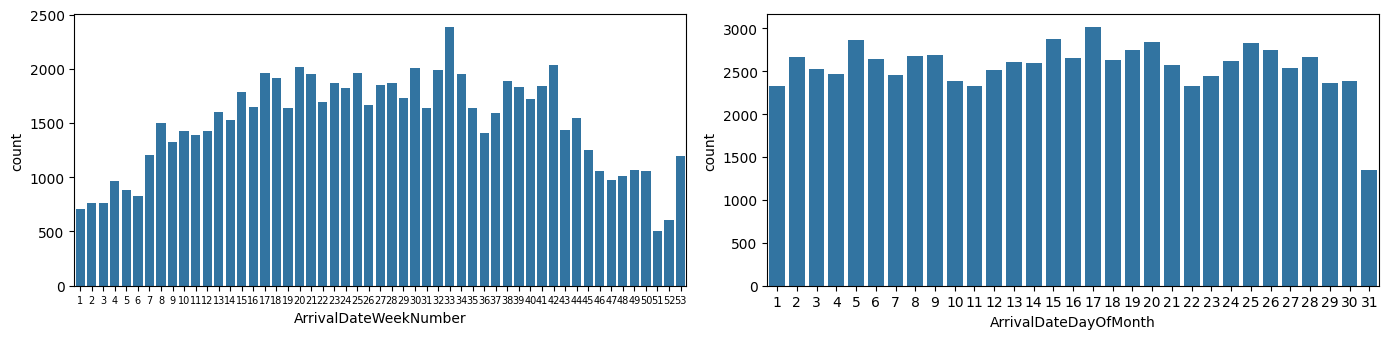

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
sns.countplot(x=booking_data["ArrivalDateWeekNumber"], ax=axes[0])
sns.countplot(x=booking_data["ArrivalDateDayOfMonth"], ax=axes[1])
axes[0].tick_params(axis="x", labelsize=7)
plt.tight_layout()

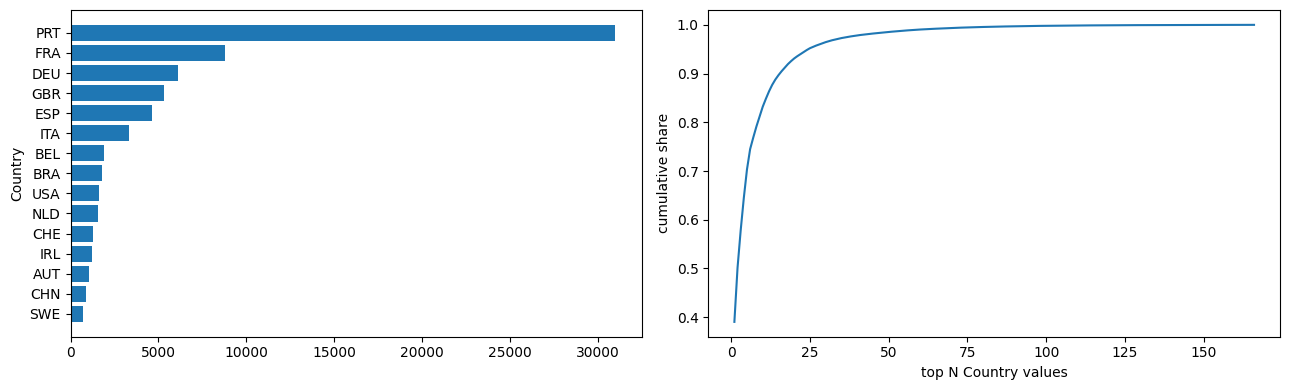

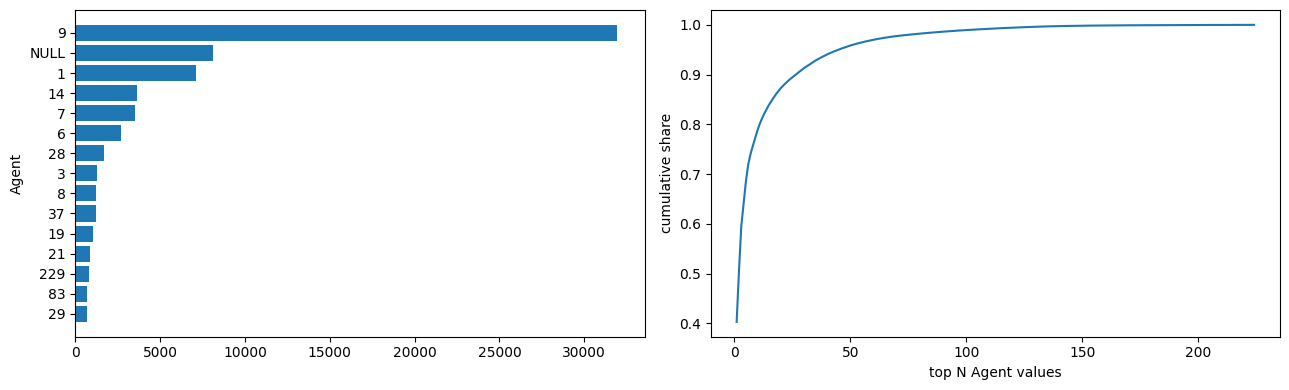

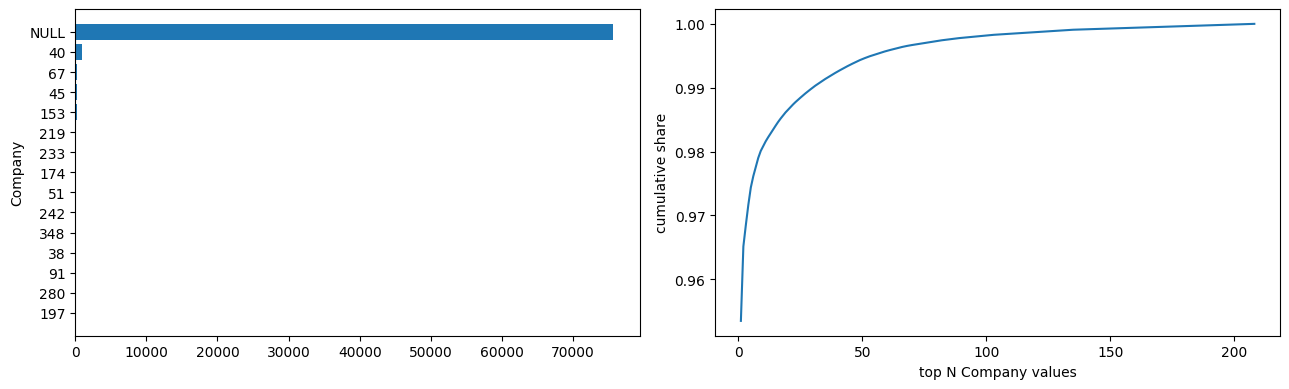

In [ ]:

for c in ["Country", "Agent", "Company"]:
    counts = booking_data[c].astype(str).str.strip().value_counts()       # strip() Because Agent and Company are padded with spaces.
    cum = counts.cumsum() / counts.sum()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].barh(counts.head(15).index, counts.head(15).values)
    axes[0].invert_yaxis()
    axes[1].plot(range(1, len(cum) + 1), cum.values)

    axes[0].set_ylabel(c)
    axes[1].set_xlabel(f"top N {c} values")
    axes[1].set_ylabel("cumulative share")
    plt.tight_layout()
    plt.show()

In [ ]:
# Agent NULL means the customer booked without an agent. This is not an error.
#        Keep it and rename it to "NoAgent".
# # Company NULL is about 95% of the rows.
#        We may make a new column "HasCompany" (1 or 0). 
#        or keep only the top companies and use "NoCompany" and "Other".

# We will keep the top values values and rename all the rare values to "Other" before encoding.

# to avoid data leakage
# Choose the top values list using the TRAIN data only.
# A value that appears only in the test data becomes "Other".

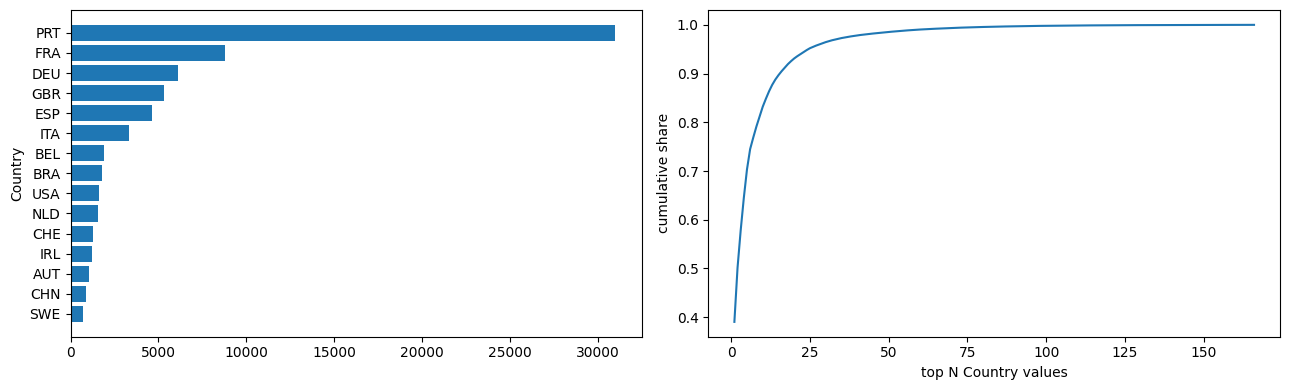

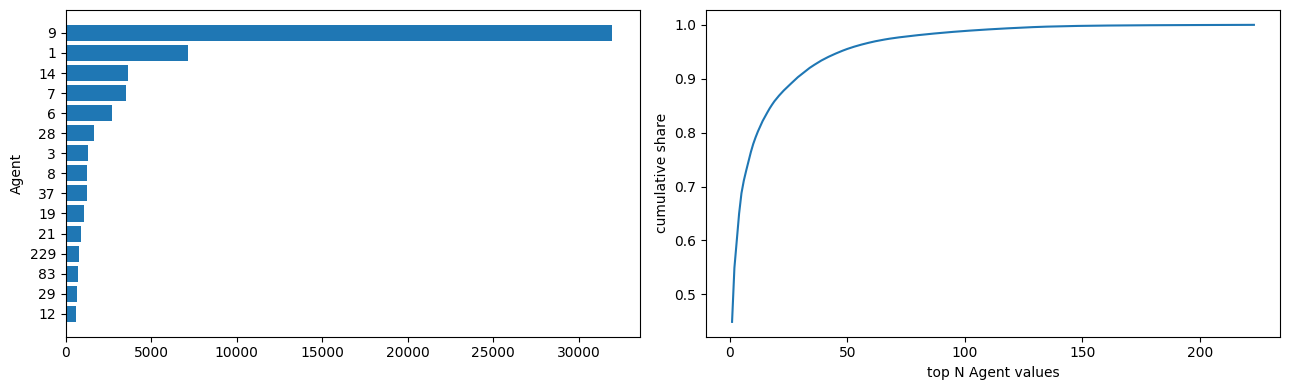

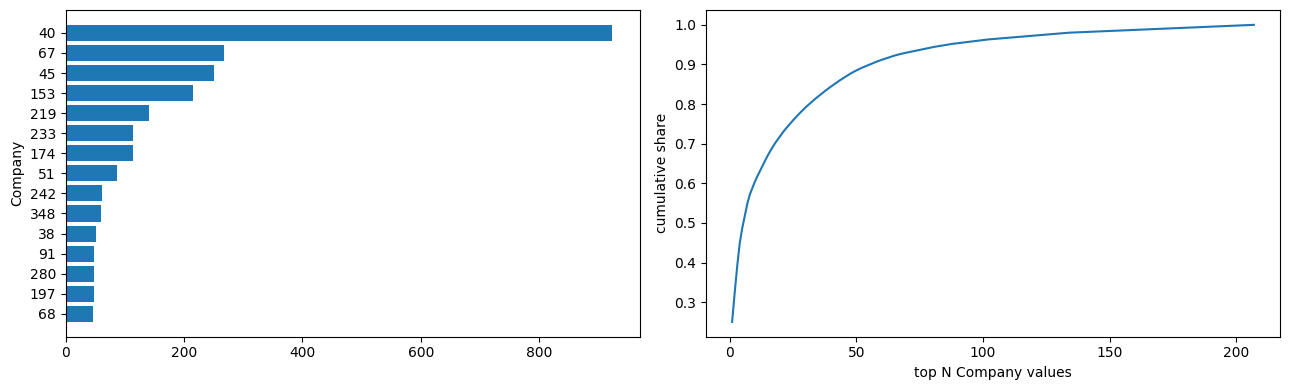

In [ ]:
# Without the Nulls
for c in ["Country", "Agent", "Company"]:
    counts = booking_data[c].astype(str).str.strip().value_counts()
    counts = counts.drop(["NULL"], errors="ignore")   # Leave out missing values
    cum = counts.cumsum() / counts.sum()    # Comulative percentage

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].barh(counts.head(15).index, counts.head(15).values)
    axes[0].invert_yaxis()
    axes[1].plot(range(1, len(cum) + 1), cum.values)

    axes[0].set_ylabel(c)
    axes[1].set_xlabel(f"top N {c} values")
    axes[1].set_ylabel("cumulative share")
    plt.tight_layout()
    plt.show()

In [ ]:
# ReservationStatus is just IsCanceled restated (crosstab showed this),
# so it would leak the answer to the classifier.
# ReservationStatusDate is only known after the outcome, so it also leaks.

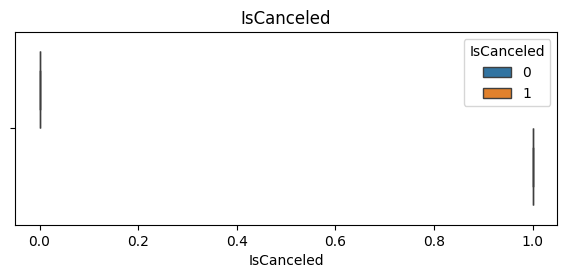

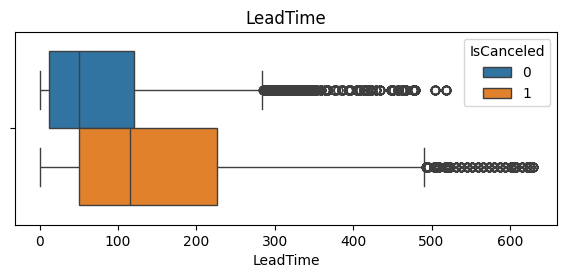

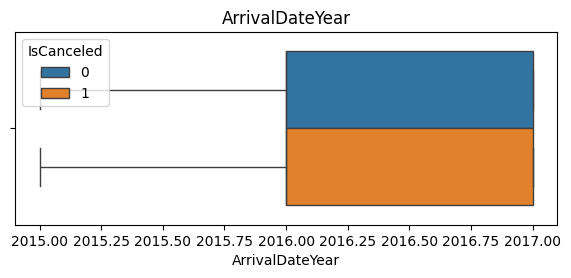

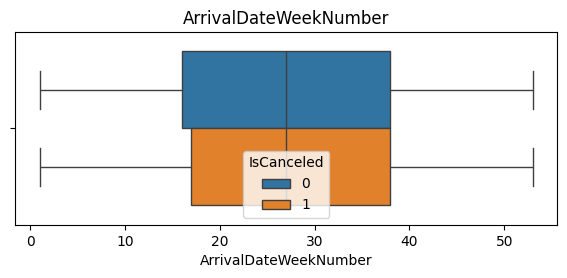

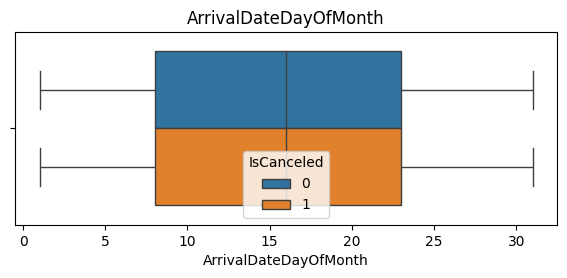

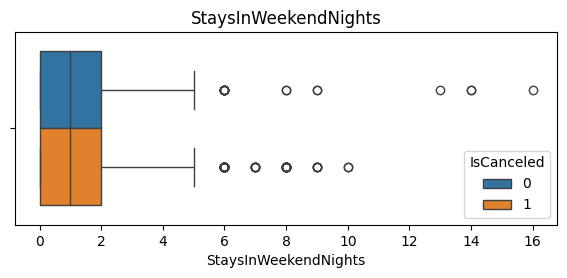

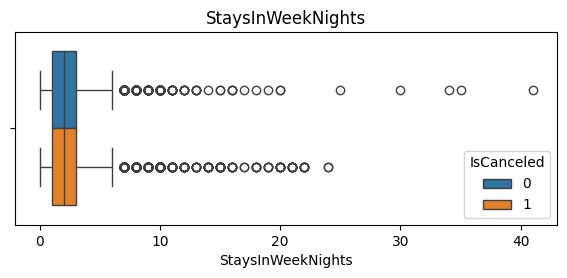

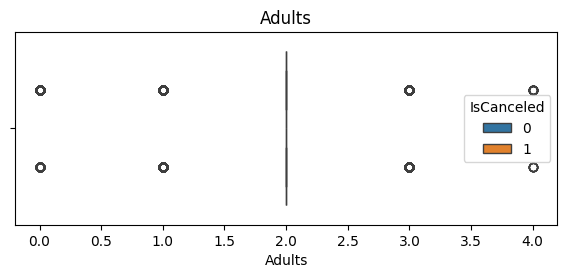

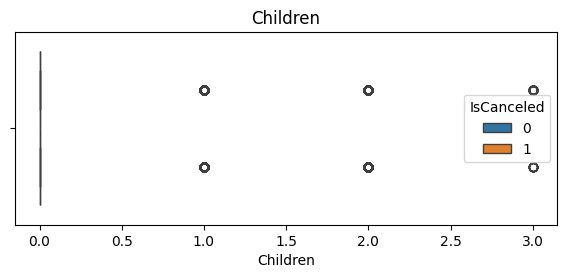

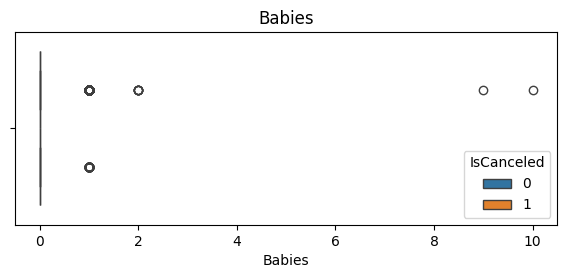

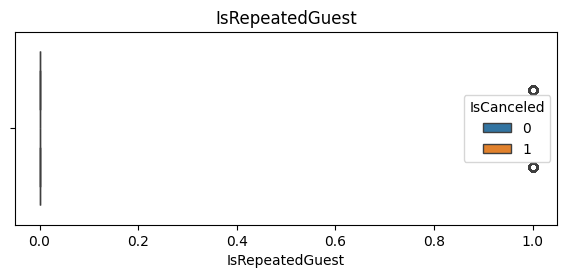

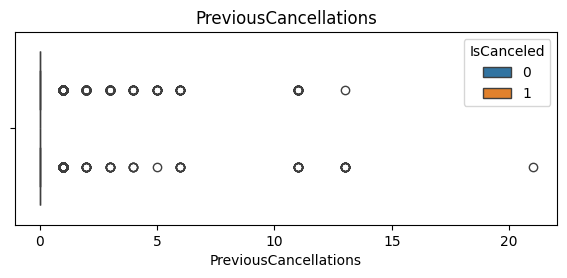

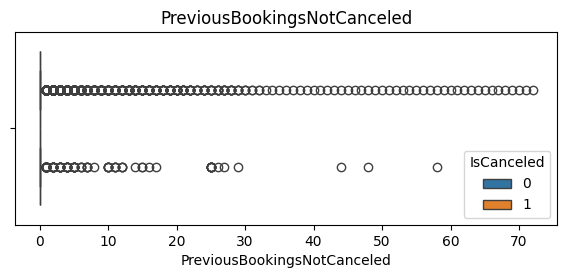

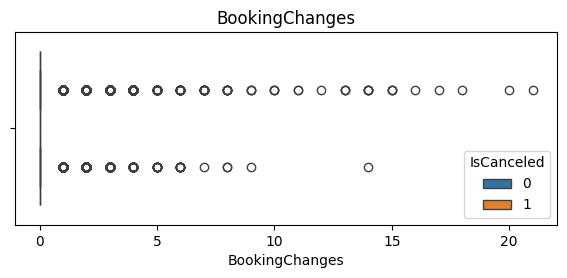

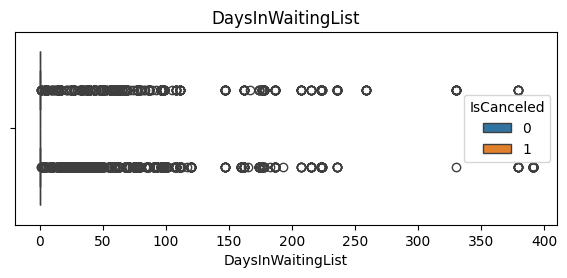

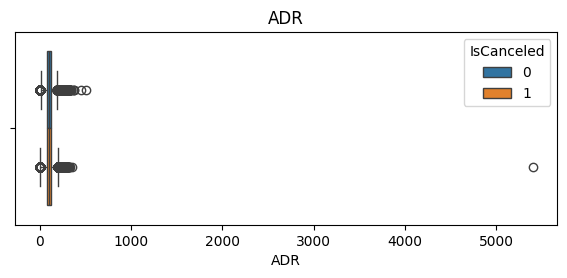

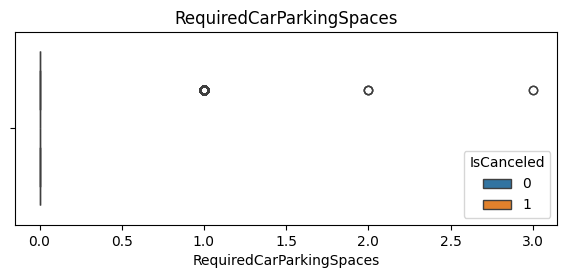

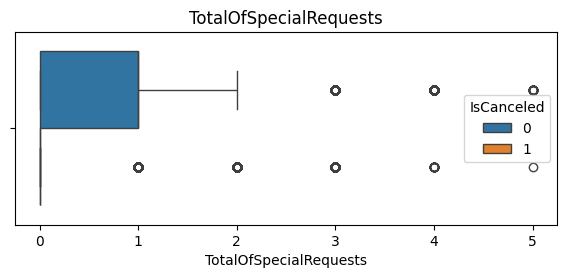

In [ ]:
num_cols = booking_data.select_dtypes(include="number").columns 
for col in num_cols:
    plt.figure(figsize=(7, 2.5))
    sns.boxplot(data=booking_data, x=booking_data[col], hue='IsCanceled')
    plt.title(col)
    plt.show()

In [ ]:
print (booking_data[booking_data['LeadTime']  > 370] .count()); 
# Number of rows where LeadTime is greater than 370 are 2646 outliers but we will not remove them as they are valid data points. The customers may have booked the hotel 1 year in advance.

IsCanceled                     2646
LeadTime                       2646
ArrivalDateYear                2646
ArrivalDateMonth               2646
ArrivalDateWeekNumber          2646
ArrivalDateDayOfMonth          2646
StaysInWeekendNights           2646
StaysInWeekNights              2646
Adults                         2646
Children                       2646
Babies                         2646
Meal                           2646
Country                        2646
MarketSegment                  2646
DistributionChannel            2646
IsRepeatedGuest                2646
PreviousCancellations          2646
PreviousBookingsNotCanceled    2646
ReservedRoomType               2646
AssignedRoomType               2646
BookingChanges                 2646
DepositType                    2646
Agent                          2646
Company                        2646
DaysInWaitingList              2646
CustomerType                   2646
ADR                            2646
RequiredCarParkingSpaces    

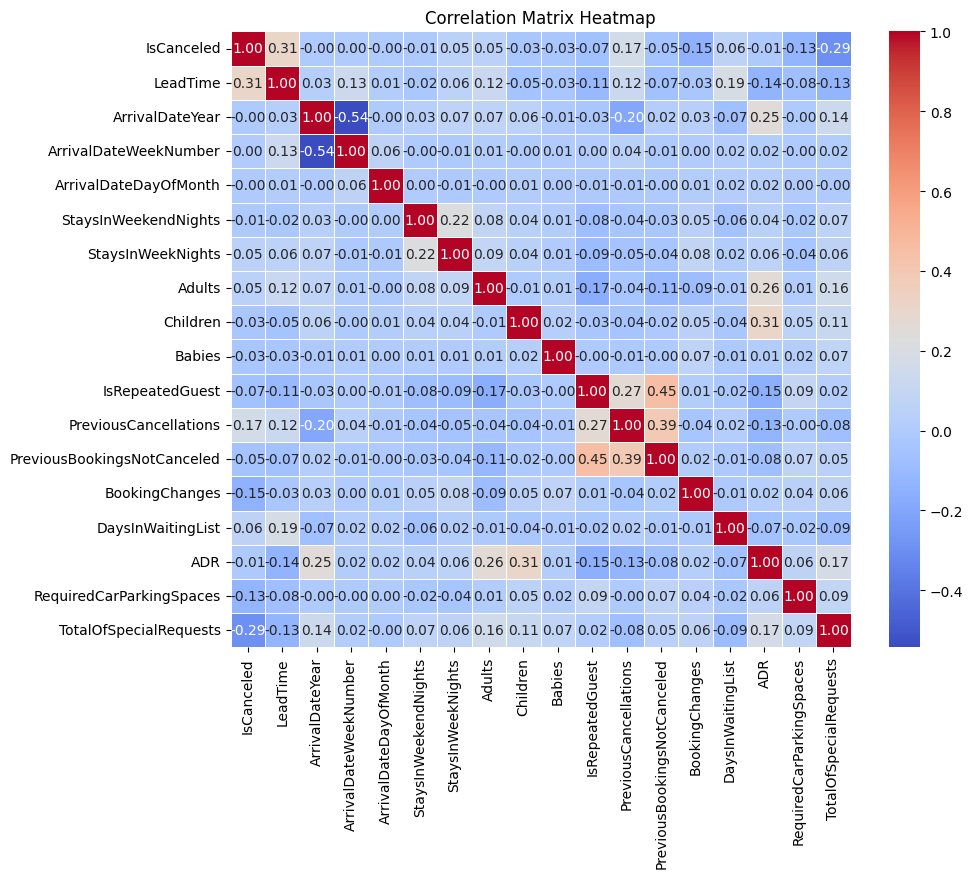

In [ ]:
numeric_booking_data = booking_data.select_dtypes(include="number")
corr_matrix = numeric_booking_data.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix Heatmap")
plt.show()

In [ ]:
# The correlation matrix shows that there are no strong correlations between the features and the target variable (IsCanceled). The highest correlation is with LeadTime (0.31), which is still relatively low. This suggests that we may need to explore feature engineering or other techniques to improve model performance.
# There is no correlation between IsCanceled and ArrivalDateYear, ArrivalDateWeekNumber, ArrivalDateDayOfMonth,StaysInWeekendNights 
# ADR has good correlation with adults, children, babies, and total of special requests. This suggests that these features may be important in predicting the price of a booking.

In [ ]:
print (booking_data[(booking_data['IsCanceled'] == 1) & (booking_data['ADR'] > 0)].count())

IsCanceled                     32973
LeadTime                       32973
ArrivalDateYear                32973
ArrivalDateMonth               32973
ArrivalDateWeekNumber          32973
ArrivalDateDayOfMonth          32973
StaysInWeekendNights           32973
StaysInWeekNights              32973
Adults                         32973
Children                       32969
Babies                         32973
Meal                           32973
Country                        32959
MarketSegment                  32973
DistributionChannel            32973
IsRepeatedGuest                32973
PreviousCancellations          32973
PreviousBookingsNotCanceled    32973
ReservedRoomType               32973
AssignedRoomType               32973
BookingChanges                 32973
DepositType                    32973
Agent                          32973
Company                        32973
DaysInWaitingList              32973
CustomerType                   32973
ADR                            32973
R

In [ ]:
# Check for rare classes in categorical columns and rare values in discrete numeric columns. 

In [ ]:
pd.set_option('display.max_rows', None)       
pd.set_option('display.max_columns', None)     
pd.set_option('display.max_colwidth', None)



booking_data.drop_duplicates(inplace=True)
print(booking_data.shape) 
print (booking_data['IsCanceled'].value_counts()) # unbalanced classes 
print (booking_data['LeadTime'].value_counts())  

(53428, 31)
IsCanceled
0    37379
1    16049
Name: count, dtype: int64
LeadTime
0      2901
1      1696
2      1036
3       963
4       950
5       854
6       792
7       703
8       652
12      609
9       581
11      562
14      548
16      542
10      527
17      493
13      487
18      481
15      472
19      448
20      444
28      435
34      400
35      398
29      394
21      390
22      386
31      368
26      353
40      352
23      351
32      350
33      349
30      349
25      348
24      344
36      339
41      335
27      334
39      318
47      305
38      302
44      299
45      294
53      292
37      287
56      282
43      276
50      276
54      275
64      275
49      273
42      269
55      268
46      268
57      262
48      254
68      250
63      249
59      245
61      243
58      242
60      241
52      236
75      234
98      234
65      229
62      229
69      229
51      224
67      223
88      221
72      219
79      214
74      214
73      210
71      